# Django 4: Views, Apps, and URL Mappings

## Table of Contents

1. [Setup: Diagram Renderer](#setup)
2. [Django Architecture: MVT vs MVC](#architecture)
3. [Creating a Django Project](#project)
4. [URL Mappings in Detail](#urls)
5. [Built-in View Types](#views)
6. [Improving Views with Interactivity](#interactivity)
7. [Expanding Django with Convenience Features](#convenience)
8. [Internationalization and Localization](#i18n)
9. [Exercises](#exercises)

---
<a id='setup'></a>
## 1. Setup: Diagram Renderer

Run the cell below once before any diagram cell. No extra packages needed — `IPython.display` is built into Jupyter.


## `render_diagram` helper

```python
from pathlib import Path
from IPython.display import Image, display

def render_diagram(image_path, width=900):
    display(Image(filename=str(image_path), width=width))
```

No extra packages required — `IPython` is built into Jupyter.


In [1]:
from pathlib import Path
from IPython.display import Image, display

def render_diagram(image_path, width=900):
    display(Image(filename=str(image_path), width=width))

DIAGRAMS = Path('assets/diagrams')
print('Ready. Diagrams:', DIAGRAMS.resolve())


Ready. Diagrams: /Users/I777690/repos/django/04-django-4-views-apps-url-mappings/assets/diagrams


---
<a id='architecture'></a>
## 2. Django Architecture: MVT vs MVC

### 2.1 The HTTP Request/Response Model

All web frameworks are built on top of the same fundamental cycle: a client sends an HTTP request, it travels over the internet/network to a server, and the server returns an HTTP response.

### 2.2 The MVC Pattern

Many web frameworks (Ruby on Rails, ASP.NET, Spring MVC) use the **Model-View-Controller** pattern:

| Component | Role |
|-----------|------|
| **Model** | Data representation — the database layer |
| **View** | Receives input, returns the display to the user |
| **Controller** | Manages data changes and routes requests |

In MVC the **Controller** sits at the top of the request flow, dispatching to the View (for rendering) and to the Model (for data).

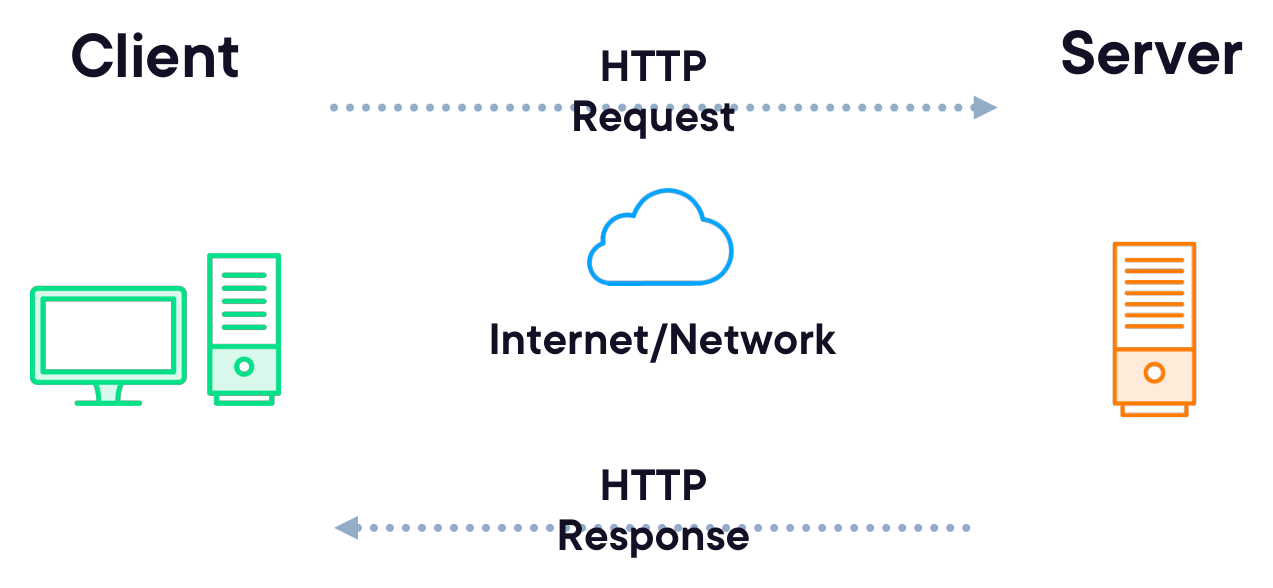

In [2]:
render_diagram(DIAGRAMS / "mvc_diagram.png")

### 2.3 Django's MVT Pattern

Django uses **Model-View-Template (MVT)**, a variation of MVC:

| Component | MVC Equivalent | Role in Django |
|-----------|---------------|----------------|
| **Model** | Model | Data representation |
| **View** | Controller | Renders a response based on Model data |
| **Template** | View | Display of data to the client |

> **Key insight:** In Django the *View* plays the Controller role. The *Template* does what MVC calls a View. The naming shift is intentional — Django wants you to think of a "view" as *what the user sees after business logic runs*, not as the routing layer.

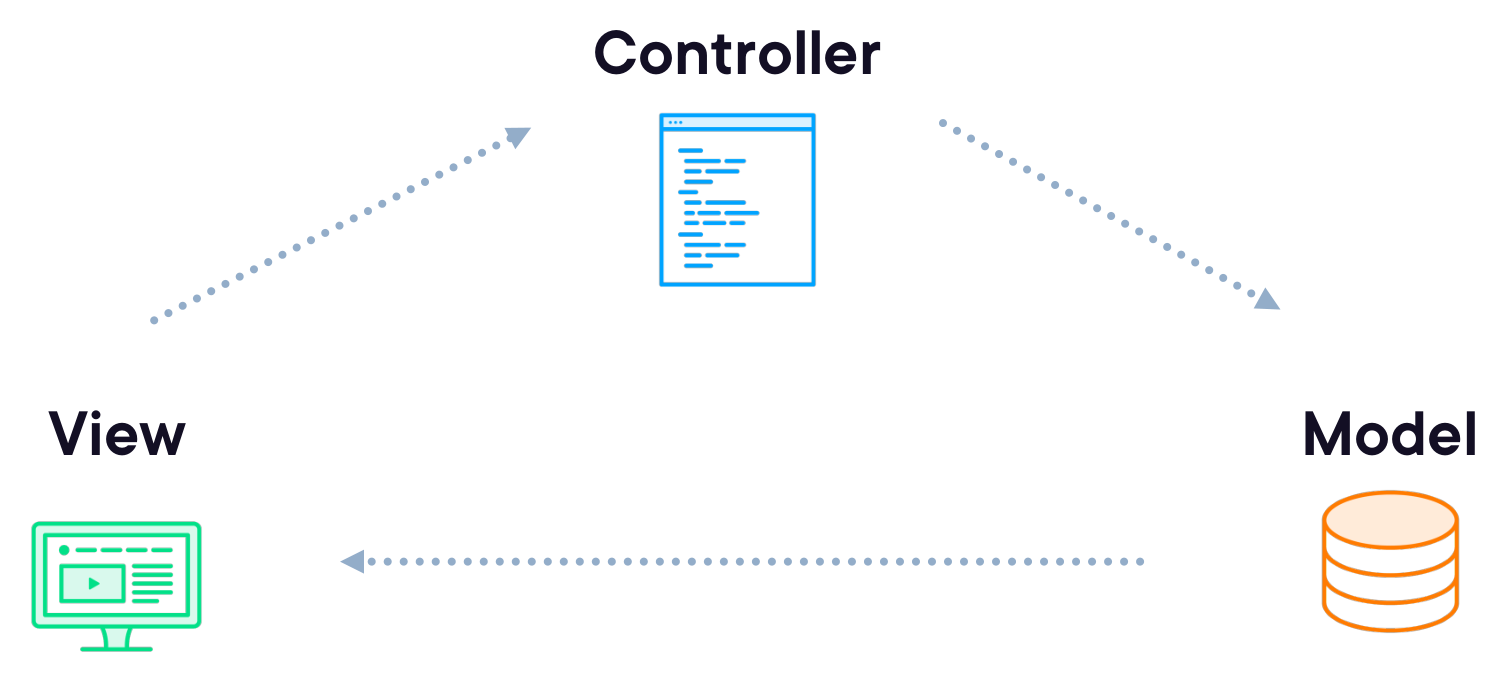

In [3]:
render_diagram(DIAGRAMS / "mvt_diagram.png")

### 2.4 Full Django MVT Request Flow

Inside the Django framework the complete flow is:

```
Client
  │
  ▼ HTTP Request
URL Dispatcher  ──────► View
                           │
                    ┌──────┴──────┐
                    ▼             ▼
                 Template       Model
                    │             │
                    └──────┬──────┘
                           ▼
  ◄──────────── HTTP Response
Client
```

**Django URL Dispatcher capabilities:**
- Regex patterns for flexible route matching
- Variable passing (typed path converters like `<int:pk>`)
- URL namespacing to avoid name collisions
- HTTP method handling (GET, POST, PUT, DELETE)
- Middleware integration

**Django View capabilities:**
- Access to multiple data sources (database, cache, external APIs)
- Varied response formats (HTML, JSON, XML, redirects)
- Extensibility through class-based views and mixins
- Standard data controls (authentication, permissions)

**Django Template capabilities:**
- Easy-to-learn template engine
- Basic logic (conditionals, loops)
- Rich set of built-in tags and filters

### 2.5 Summary

- MVT is conceptually the same as MVC with renamed roles.
- The URL dispatcher is Django's equivalent of the MVC controller entry point.
- Separating the template from the view keeps display logic out of Python code.

---
<a id='project'></a>
## 3. Creating a Django Project

### 3.1 Project and Application Structure

A Django **project** is the top-level container. Inside it you create one or more **applications** (apps). The standard file layout is:

```
DjangoProject/
├── /core/                  ← project package (named at creation time)
│   ├── asgi.py
│   ├── settings.py         ← global configuration
│   ├── urls.py             ← root URL configuration
│   └── wsgi.py
├── /application/           ← one app (repeat for each app)
│   ├── /migrations/
│   ├── admin.py
│   ├── apps.py
│   ├── models.py
│   ├── views.py
│   └── tests.py
└── manage.py
```

### 3.2 Key Files

**`settings.py`** — holds project configuration loaded at startup and used globally:

```python
# SECURITY WARNING: don't run with debug turned on in production!
DEBUG = True
ALLOWED_HOSTS = []

INSTALLED_APPS = [
    'django.contrib.admin',
    'django.contrib.auth',
    'django.contrib.contenttypes',
    'django.contrib.sessions',
    'django.contrib.messages',
    'django.contrib.staticfiles',
    'forum',            # ← your app goes here
]
```

**`urls.py`** — the central entry point; defines paths to Django views:

```python
from django.contrib import admin
from django.urls import path, include

urlpatterns = [
    path('admin/', admin.site.urls),
    path('forum/', include('forum.urls')),  # delegate to app-level urls
]
```

### 3.3 Environment Setup

Recommended setup sequence on macOS/Linux:

```bash
# Verify Python
python --version

# Install virtualenv
pip3 install virtualenv

# Create project folder and virtual environment
mkdir forumdjango
cd forumdjango
virtualenv venv

# Activate and install Django
source venv/bin/activate
pip3 install Django

# Verify Django version
django-admin --version
```

### 3.4 Creating the Project and App

```bash
# Create project (creates the core/ package and manage.py)
django-admin startproject core .

# Create an application
python manage.py startapp forum

# Run the development server
python manage.py runserver
```

### 3.5 Demo: Models

The demo project uses a simple forum with `Post` and `Comment` models:

# forum/models.py  (from 03/demos)

```python
from django.db import models
from django.conf import settings

class Post(models.Model):
    title = models.CharField(max_length=100)
    body = models.TextField(null=True, blank=True)
    user = models.ForeignKey(
        settings.AUTH_USER_MODEL,
        null=True, blank=True,
        on_delete=models.CASCADE,
        related_name="posts"
    )

class Comment(models.Model):
    user = models.ForeignKey(
        settings.AUTH_USER_MODEL,
        null=True, blank=True,
        on_delete=models.CASCADE,
        related_name="comments"
    )
    post = models.ForeignKey(
        Post, null=True, blank=True,
        on_delete=models.CASCADE,
        related_name="comments"
    )
    body = models.TextField(null=True, blank=True)
```


After defining models, apply them to the database:

```bash
python manage.py makemigrations
python manage.py migrate
```

---
<a id='urls'></a>
## 4. URL Mappings in Detail

### 4.1 URL Structure Overview

Django's URL system supports:
- **Clean configurations** with readable path strings
- **Path converters** for typed parameter capture
- **Regular expressions** for complex matching
- **Error handling** for missing or broken URLs

### 4.2 Basic URL Patterns with `path()`

# forum/urls.py  (from 04/demos — illustrative, not runnable standalone)

```python
from django.urls import path, re_path
from .views import index, PostListView, PostDetailView, CommentListView

urlpatterns = [
    # ex: /forum/
    path('', index, name='index'),

    # ex: /forum/5/
    path('<int:pk>/', PostDetailView.as_view(), name='detail'),

    # ex: /forum/5/comment/
    path('<int:post_id>/comment/', CommentListView.as_view(), name='comment'),
]
```


**Built-in path converters:**

| Converter | Matches | Example |
|-----------|---------|----------|
| `str` | Any non-empty string (default) | `<str:slug>` |
| `int` | Zero or positive integer | `<int:pk>` |
| `slug` | ASCII letters, numbers, hyphens, underscores | `<slug:slug>` |
| `uuid` | UUID string | `<uuid:id>` |
| `path` | Any non-empty string including `/` | `<path:subpath>` |

### 4.3 Regular Expression Patterns with `re_path()`

# forum/urls.py — regex patterns  (from 04/demos)

```python
from django.urls import re_path

urlpatterns = [
    # ex: /posts/2023
    re_path(r'^posts/(?P<year>[0-9]{4})/$', PostListView.as_view(), name='by_year'),

    # ex: /posts/2023/3
    re_path(r'^posts/(?P<year>[0-9]{4})/(?P<month>[0-9]{2})/$',
            PostListView.as_view(), name='by_month'),

    # ex: /posts/2023/3/post-slug
    re_path(r'^posts/(?P<year>[0-9]{4})/(?P<month>[0-9]{2})/(?P<slug>[\\w-]+)/$',
            PostListView.as_view(), name='slug_detail'),
]
```


### 4.4 Including App-Level URL Configurations

Keep your project's root `urls.py` clean by delegating to each app:

```python
# core/urls.py
from django.contrib import admin
from django.urls import path, include

urlpatterns = [
    path('admin/', admin.site.urls),
    path('forum/', include('forum.urls')),       # all /forum/* routes
    path('pages/', include('django.contrib.flatpages.urls')),
    path('__debug__/', include('debug_toolbar.urls')),
]
```

### 4.5 Error Handlers

Override Django's default error pages by assigning handler variables in the **root** `urls.py`:

```python
# In core/urls.py (root URLconf only)
Handler400 = 'myapp.views.custom_bad_request_view'
Handler403 = 'myapp.views.custom_permission_denied_view'
Handler404 = 'forum.views.custom_page_not_found_view'
Handler500 = 'myapp.views.custom_server_error_view'
```

### 4.6 URL Reversals

Generate a URL from a view name and arguments using `reverse()`. This keeps URLs DRY — change the URL pattern once and all `reverse()` calls update automatically.

```python
from django.urls import reverse
from django.http import HttpResponseRedirect

# Signature:
# reverse(viewname, urlconf=None, args=None, kwargs=None, current_app=None)

# Basic reversal
url = reverse('detail', args=[123])   # → '/forum/123/'
return HttpResponseRedirect(url)

# Namespaced reversal (after: path('tech-forum/', include('forum.urls', namespace='tech-forum')))
url = reverse('tech-forum:detail', args=[123])  # → '/tech-forum/123/'
```

### 4.7 URL Namespacing

When including app URLs, pass a `namespace` argument to scope all named patterns:

```python
# core/urls.py
path('tech-forum/', include('forum.urls', namespace='tech-forum')),

# Then in templates:
# {% url 'tech-forum:detail' post.pk %}
# And in views:
# reverse('tech-forum:detail', args=[post.pk])
```

---
<a id='views'></a>
## 5. Built-in View Types

### 5.1 Function-Based Views (FBVs)

The simplest view type: a Python function that takes a `request` and returns a response.

# forum/views.py — FBV  (from 05/demos)

```python
from django.http import HttpResponse

def index(request):
    return HttpResponse('<html><body>Our First Response.</body></html>')
```


### 5.2 Class-Based Views (CBVs)

CBVs encapsulate view logic in a class, enabling:
- Code reuse through inheritance
- Clean separation of GET/POST handling
- Mixin composition for cross-cutting concerns

**Core generic views:**

| CBV | Purpose |
|-----|---------|
| `View` | Base class; override `get()`, `post()` etc. |
| `TemplateView` | Render a template with optional context |
| `ListView` | Display a list of model objects |
| `DetailView` | Display a single model object |
| `FormView` | Handle form submission |

### 5.3 ListView

# forum/views.py — ListView  (from 05/demos)

```python
from django.http import HttpResponse
from django.views.generic.list import ListView
from forum.models import Post

class PostListView(ListView):
    model = Post
    context_object_name = 'post_data'      # name used in template

    def get_queryset(self):
        """Optionally filter by year/month URL kwargs."""
        self.queryset = Post.objects.all()
        if self.kwargs.get('year'):
            self.queryset = self.queryset.filter(created_at__year=self.kwargs['year'])
        if self.kwargs.get('month'):
            self.queryset = self.queryset.filter(created_at__month=self.kwargs['month'])
        return self.queryset

    def render_to_response(self, context, **response_kwargs):
        """Override to return a custom HTML response instead of a template."""
        posts = ''.join(f'<li>{post.title}</li>' for post in context['post_data'])
        return HttpResponse(f'<html><body><ul>{posts}</ul></body></html>')
```


### 5.4 DetailView

# forum/views.py — DetailView  (from 05/demos)

```python
from django.views.generic.detail import DetailView
from forum.models import Post

class PostDetailView(DetailView):
    model = Post

    def render_to_response(self, context, **response_kwargs):
        post = context.get('object')
        return HttpResponse(
            f'<ul>'
            f'<li>Title:{post.title}</li>'
            f'<li>Body:{post.body}</li>'
            f'<li>User:{post.user.first_name}</li>'
            f'</ul>'
        )
```


### 5.5 TemplateView

# forum/views.py — TemplateView  (from 06/demos and 08/demos)

```python
from django.views.generic.base import TemplateView
from datetime import datetime

class TestTemplateView(TemplateView):
    template_name = 'test_template.html'

    def get_context_data(self, **kwargs):
        context = super().get_context_data(**kwargs)
        context["today"] = datetime.now().date()   # inject extra context
        return context
```


### 5.6 CBV Mixins

Mixins add reusable behaviour to CBVs without deep inheritance chains.

| Mixin | Class Path | Purpose |
|-------|-----------|----------|
| `TemplateResponseMixin` | `django.views.generic.base` | Provides `render_to_response()` |
| `ContextMixin` | `django.views.generic.base` | Provides `get_context_data()` |
| `SuccessMessageMixin` | `django.contrib.messages.views` | Adds flash message on FormView success |

**ContextMixin** — supplies the template with extra data:

```python
class django.views.generic.base.ContextMixin

    def get_context_data(self, **kwargs):
        # override to add data to the template context
        ...
```

**SuccessMessageMixin** — used with `FormView` to provide formatted success messages:

```python
class views.SuccessMessageMixin

    def get_success_message(self, cleaned_data):
        # override to customise the success message
        ...
```

### 5.7 CBV Decorators

Decorators pre-process requests. They can be applied at the URLconf level or directly on the class/method.

**At the URLconf level:**

```python
from django.contrib.auth.decorators import login_required

path("about/", login_required(TemplateView.as_view(template_name="protect.html")))
```

**On the class with `@method_decorator`:**

```python
from django.contrib.auth.decorators import login_required
from django.contrib.auth.mixins import LoginRequiredMixin
from django.utils.decorators import method_decorator
from django.views.decorators.cache import never_cache
from django.views.generic.base import TemplateView

@method_decorator(never_cache, name="dispatch")
class ProtectedView(LoginRequiredMixin, TemplateView):
    template_name = "secret.html"

    @method_decorator(login_required)
    def dispatch(self, *args, **kwargs):
        return super().dispatch(*args, **kwargs)
```


### 5.8 Overriding `render_to_response`

Customise the final response format (e.g., serve JSON for API clients):

```python
from django.views.generic.detail import DetailView
from forum.models import Post

class PostDetailView(DetailView):
    model = Post

    def render_to_response(self, context, **response_kwargs):
        if self.request.GET.get("format") == "json":
            # return a JSON response
            pass
        else:
            return super().render_to_response(context, **response_kwargs)
```


### 5.9 HTTP Method Handlers

Use `View` directly to handle different HTTP methods explicitly:

```python
from django.views import View

class MyFormView(View):

    def get(self, request, *args, **kwargs):
        # handle GET request — typically render the empty form
        pass

    def post(self, request, *args, **kwargs):
        # handle POST request — typically process form submission
        pass
```


### 5.10 Pagination

**Built-in ListView pagination** — add `paginate_by` to enable it automatically:

```python
class ArticleListView(ListView):
    model = Article
    paginate_by = 100   # 100 items per page
```

**Manual pagination** using `Paginator`:

```python
from django.core.paginator import Paginator

# paginate any list
paginator = Paginator(transactions, 10)  # 10 items per page
page_obj = paginator.get_page(2)         # get page 2

# page_obj attributes:
# page_obj.object_list     — queryset for this page
# page_obj.has_previous()  — bool
# page_obj.has_next()      — bool
# page_obj.previous_page_number()
# page_obj.next_page_number()
```


---
<a id='interactivity'></a>
## 6. Improving Views with Interactivity

### 6.1 Sessions

Sessions let you persist user-specific data across requests. Django's `SessionMiddleware` is enabled by default.

**Session storage backends** (configured via `SESSION_ENGINE`):

| Backend | Setting value |
|---------|---------------|
| Database (default) | `django.contrib.sessions.backends.db` |
| File system | `django.contrib.sessions.backends.file` |
| Cache | `django.contrib.sessions.backends.cache` |
| Signed cookies | `django.contrib.sessions.backends.signed_cookies` |

**Using sessions in a view** (from `06/demos/forum/views.py`):

```python
from datetime import datetime
from django.http import HttpResponse

class PostListView(ListView):
    model = Post
    context_object_name = 'post_data'

    def render_to_response(self, context, **response_kwargs):
        # Read a session value
        first_viewed = self.request.session.get('first_viewed', False)
        if first_viewed:
            return HttpResponse(f'You first viewed on {first_viewed}.')

        # Write a session value
        self.request.session['first_viewed'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
        ...

def index(request):
    request.session.clear()   # clear all session data
    ...
```


**Session expiry** — set via `set_expiry(value)`:

```python
request.session.set_expiry(300)   # expire after 300 seconds of inactivity
request.session.set_expiry(0)     # expire when browser closes
request.session.set_expiry(None)  # use global SESSION_COOKIE_AGE
```

### 6.2 Messages Framework

The Django messages framework (`django.contrib.messages`) enables one-time flash messages — set in one request, consumed in the next.

**Built-in message levels:** `DEBUG`, `INFO`, `SUCCESS`, `WARNING`, `ERROR`

**Adding and reading messages** (from `06/demos/forum/views.py`):

```python
from django.contrib import messages
from django.contrib.messages import get_messages

# Add a message
def index(request):
    messages.add_message(request, messages.INFO, 'Hello world!')
    ...

# Consume messages in a view
def some_view(request):
    storage = get_messages(request)
    message_html = ''.join(f'<li>{msg}</li>' for msg in storage)
    ...
```


**Consuming messages in a template:**

```html
{% if messages %}
<ul class="messages">
    {% for message in messages %}
    <li{% if message.tags %} class="{{ message.tags }}"{% endif %}>{{ message }}</li>
    {% endfor %}
</ul>
{% endif %}
```

### 6.3 Static Files

Static files (CSS, JS, images) are served via `django.contrib.staticfiles`.

**Template usage** (from `06/demos/forum/templates/test_template.html`):

```html
<!DOCTYPE html>
<html lang="en">
<head>
    {% load static %}
    <link rel="stylesheet" href="{% static 'styles.css' %}">
</head>
<body>
    <div class="red">This should be red.</div>
</body>
</html>
```

**Collect static files for deployment:**

```bash
python manage.py collectstatic
```

Key settings:

```python
STATIC_URL = 'static/'          # URL prefix
STATIC_ROOT = BASE_DIR / 'staticfiles'  # where collectstatic writes
```

---
<a id='convenience'></a>
## 7. Expanding Django with Convenience Features

### 7.1 Flatpages

`django.contrib.flatpages` lets you create simple HTML pages managed through the admin, without writing views.

**Setup:**

```python
# settings.py
SITE_ID = 1
INSTALLED_APPS = [
    ...
    'django.contrib.sites',
    'django.contrib.flatpages',
]
MIDDLEWARE = [
    ...
    'django.contrib.flatpages.middleware.FlatpageFallbackMiddleware',
]

# urls.py
path('pages/', include('django.contrib.flatpages.urls')),
```

**Flatpage template** (from `07/demos/forum/templates/flatpages/default.html`):

```html
<!DOCTYPE HTML>
<html>
    <head><title>{{ flatpage.title }}</title></head>
    <body>{{ flatpage.content }}</body>
</html>
```

### 7.2 Signals

Signals decouple components by letting senders notify receivers when events occur.

**Built-in signals:**

| Signal | Fires when |
|--------|------------|
| `pre_save` | Before a model's `save()` |
| `post_save` | After a model's `save()` |
| `pre_delete` | Before a model's `delete()` |
| `post_delete` | After a model's `delete()` |
| `request_finished` | After Django delivers an HTTP response |

**Connecting a signal** (from `07/demos/forum/views.py`):

```python
from django.core.signals import request_finished
from django.core.mail import send_mail

def my_callback(sender, **kwargs):
    print('Request finished!')
    send_mail(
        'subject of some sort',
        'here is the message.',
        'from@example.com',
        ['to@example.com'],
        fail_silently=False,
    )

request_finished.connect(my_callback)
```


Using the `@receiver` decorator (alternative to `.connect()`):

```python
from django.db.models.signals import post_save
from django.dispatch import receiver
from forum.models import Post

@receiver(post_save, sender=Post)
def post_saved_handler(sender, instance, created, **kwargs):
    if created:
        print(f'New post created: {instance.title}')
```

### 7.3 Email

Django's email framework sends email through a configurable backend.

**Email backends:**

| Backend | Setting value | Use |
|---------|--------------|-----|
| SMTP | `django.core.mail.backends.smtp.EmailBackend` | Production |
| Console | `django.core.mail.backends.console.EmailBackend` | Development |
| File | `django.core.mail.backends.filebased.EmailBackend` | Testing |
| In-memory | `django.core.mail.backends.locmem.EmailBackend` | Unit tests |
| Dummy | `django.core.mail.backends.dummy.EmailBackend` | Discard all |

**Sending email** (used in `07/demos` and `08/demos`):

```python
# settings.py
EMAIL_BACKEND = 'django.core.mail.backends.console.EmailBackend'

# views.py
from django.core.mail import send_mail

send_mail(
    'Subject here',
    'Here is the message.',
    'from@example.com',
    ['to@example.com'],
    fail_silently=False,
)
```

### 7.4 Syndication (RSS/Atom Feeds)

Create RSS/Atom feeds by subclassing `django.contrib.syndication.views.Feed`.

**Feed class** (from `07/demos/forum/forum_feeds.py`):

```python
from django.contrib.syndication.views import Feed
from django.urls import reverse
from forum.models import Post

class LatestPostFeed(Feed):
    title = 'Our Posts'
    link = '/latest/posts'
    description = 'Latest posts made.'

    def items(self):
        return Post.objects.order_by('-created_at')[:5]

    def item_title(self, item):
        return item.title

    def item_description(self, item):
        return item.body

    def item_link(self, item):
        return reverse('detail', args=[item.pk])
```


**Register the feed in `urls.py`:**

```python
from forum.forum_feeds import LatestPostFeed

urlpatterns = [
    path('latest/posts/', LatestPostFeed()),
    ...
]
```

### 7.5 System Checks

Django runs internal consistency checks at startup. You can write your own:

```python
from django.core.checks import Error, register

@register()
def example_check(app_configs, **kwargs):
    errors = []
    # ... your check logic here ...
    if check_failed:
        errors.append(
            Error(
                "an error",
                hint="A hint.",
                obj=checked_object,
                id="myapp.E001",
            )
        )
    return errors
```

Run checks manually:

```bash
python manage.py check
```

### 7.6 Django Debug Toolbar

An invaluable development tool that shows SQL queries, template context, cache hits, and more.

**Installation:**

```bash
python -m pip install django-debug-toolbar
```

**Settings** (from `07/demos/core/settings.py`):

```python
INSTALLED_APPS = [
    ...
    'debug_toolbar',
]
MIDDLEWARE = [
    ...
    'debug_toolbar.middleware.DebugToolbarMiddleware',
]
INTERNAL_IPS = [
    '127.0.0.1',
]
```

**URL registration** (from `07/demos/core/urls.py`):

```python
path('__debug__/', include('debug_toolbar.urls')),
```

The toolbar only displays when `DEBUG = True` and the request comes from an `INTERNAL_IPS` address.

---
<a id='i18n'></a>
## 8. Internationalization and Localization

### 8.1 Overview

| Concept | Abbreviation | What it covers |
|---------|-------------|----------------|
| Internationalization | i18n | Marking strings for translation |
| Localization | l10n | Formatting numbers, dates, currencies |

### 8.2 Settings

**From `08/demos/core/settings.py`:**

```python
USE_I18N = True
LANGUAGE_CODE = 'en'

MIDDLEWARE = [
    ...
    'django.middleware.locale.LocaleMiddleware',  # detects user language
    ...
]

LOCALE_PATHS = (
    os.path.join(BASE_DIR, 'locale'),
    os.path.join(BASE_DIR, 'forum', 'locale'),
)

# For localization:
# USE_L10N = True  # (deprecated in Django 4.0, enabled by default)
```

### 8.3 Marking Strings for Translation

**In Python code:**

```python
from django.utils.translation import gettext as _

output = _("We want this translated.")
```

**In templates** (from `08/demos/forum/templates/test_template.html`):

```html
{% load i18n %}

<!-- Simple string translation -->
<div>{% translate "This should be red." %}</div>

<!-- Block with variables -->
{% blocktranslate with name=user.get_full_name %}
    My name is {{ name }}.
{% endblocktranslate %}
```

### 8.4 Translation Workflow

```bash
# 1. Extract all translatable strings into .po files
django-admin makemessages --locale=de

# 2. Edit the generated .po file with translations
# (locale/de/LC_MESSAGES/django.po)

# 3. Compile to binary .mo files
django-admin compilemessages --locale=de
```

### 8.5 Localization Template Tags

**From `08/demos/forum/templates/test_template.html`:**

```html
{% load l10n %}

<!-- Localized (respects FORMAT_MODULE_PATH) -->
<div>{{ today }}</div>

<!-- Force unlocalized (raw Python format) -->
<div>{{ today|unlocalize }}</div>

<!-- Wrap a block in localize on/off -->
{% localize on %}
    {{ some_value }}
{% endlocalize %}
```

### 8.6 Custom Number/Date Formats

Point Django to per-locale format modules:

```python
FORMAT_MODULE_PATH = ['mysite.formats', 'some_app.formats']
```

Each entry is a Python package containing a `formats/` directory with locale-specific Python files (e.g., `de/formats.py`) that define `DATE_FORMAT`, `NUMBER_GROUPING`, etc.

---
<a id='exercises'></a>
## 9. Exercises

These exercises reinforce the concepts from each module. They assume a working Django 4.x project with the `forum` app from the demos.

---

### Exercise 1 — Architecture

Without looking at the diagrams, draw (or describe in words) the full Django MVT request/response flow starting from a browser request and ending with the rendered HTML response. Include: client, URL dispatcher, view, template, model, database.

---

### Exercise 2 — Project Setup

1. Create a new Django project called `blog` with an app called `posts`.
2. Define a `Post` model with fields: `title` (CharField), `body` (TextField), `published_at` (DateTimeField, auto_now_add).
3. Run migrations and verify the table exists in `db.sqlite3`.

---

### Exercise 3 — URL Mappings

In the `forum` app:
1. Add a URL pattern `/forum/search/` that routes to a new `SearchView`.
2. Add a `re_path` that matches `/forum/archive/YYYY/MM/` and passes `year` and `month` as kwargs.
3. Write a `reverse()` call that generates the URL for `by_year` with `year=2024`.

---

### Exercise 4 — Class-Based Views

1. Create a `PostListView` that filters posts by the authenticated user (`request.user`).
2. Add `paginate_by = 5` and confirm pagination works by adding 6+ posts.
3. Override `get_context_data` to inject the current date into the template context.

---

### Exercise 5 — Sessions and Messages

1. In a view, store the timestamp of a user's first visit in the session.
2. On subsequent visits, display `"You first visited on <timestamp>"` instead of the normal page.
3. Add a `messages.SUCCESS` message on successful form submission that disappears after one page load.

---

### Exercise 6 — Convenience Features

1. Install and configure `django-debug-toolbar`. Visit `/forum/` and inspect the SQL panel — how many queries does the page make?
2. Create an RSS feed for the 10 most recent `Post` objects.
3. Connect a `post_save` signal on `Post` that prints the post title to the console whenever a post is created.

---

### Exercise 7 — Internationalization

1. Add `LocaleMiddleware` to your project and set `LANGUAGE_CODE = 'fr'`.
2. Mark the string `"Welcome to our forum"` for translation in a view.
3. Run `makemessages` for French, provide a translation, compile, and verify the translated string appears in the browser.